# 01_eda: data, features and fair tests (step 5)

**Owner:** Joseph · **Write-up in plain words:** [`learnings/05_features.md`](../learnings/05_features.md) · **Decisions:** ADRs [0008](../docs/adr/0008-borrower-history.md), [0009](../docs/adr/0009-macro-clues.md), [0010](../docs/adr/0010-validation-tests.md), [0012](../docs/adr/0012-final-feature-set.md)

What this notebook does, in order:
1. **Looks at the data** (the brief's EDA): how rare defaults are, missing values, skew, categories, overlap, Kenya vs Ghana, and how defaults change over time.
2. **Looks at loan histories:** what we can know about a borrower's past.
3. **Builds the clues** with `src/features.py` and runs its self-checks.
4. **Compares three kinds of test** and shows how much the naive one inflates scores.
5. **Tries every option:** every combination of clue groups, every column removed, every variant, both models.
6. **Checks the noise** with a bootstrap, and **checks Task 1** (loan amount).

**Team rules:** every step is explained before and after. Only counts and summaries are printed, never data rows (course AI rule, [ADR 0003](../docs/adr/0003-data-handling.md)). Runs top to bottom in about 8 minutes on 8 cores.

In [1]:
import sys, itertools, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")
from features import build, to_loans, borrower_history, add_folds, splits, load_macro, BASE, CALENDAR, MACRO, FEATURES, preprocessor

DATA = "../data/zindi"
FIG, TAB = "../learnings/figures", "../learnings/tables"
import os; os.makedirs(FIG, exist_ok=True); os.makedirs(TAB, exist_ok=True)
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#52514e",
                     "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
BLUE, ORANGE, RED, INK2 = "#2a78d6", "#eb6834", "#e34948", "#52514e"
P = ["disbursement_date", "due_date"]
tr = pd.read_csv(f"{DATA}/Train.csv", parse_dates=P)
te = pd.read_csv(f"{DATA}/Test.csv", parse_dates=P)
print("train", tr.shape, "| test", te.shape)

train (68654, 16) | test (18594, 15)


## 1. The data at a glance (brief Part B.1)

**How rare is default?** Out of every 100 loans, about 2 aren't paid back. A model that says "everyone pays" is 98% accurate and completely useless. That's why we use PR-AUC (how well it finds the rare defaulters), not accuracy.

In [2]:
print("loans that defaulted:", int(tr.target.sum()), "of", len(tr), f"({tr.target.mean():.2%})")
print("missing values in train:", int(tr.isna().sum().sum()), "| in test:", int(te.isna().sum().sum()))
print("test rows by country:", te.country_id.value_counts().to_dict())

loans that defaulted: 1258 of 68654 (1.83%)
missing values in train: 0 | in test: 0
test rows by country: {'Kenya': 15069, 'Ghana': 3525}


**Skew.** Loan amounts range from tiny to millions. A few huge loans would dominate any average, so we use the *log* of amounts. The log turns 100 → 1,000 → 10,000 into evenly spaced steps.

In [3]:
a = tr.Total_Amount
print(f"amount: smallest {a.min():,.0f} | middle {a.median():,.0f} | average {a.mean():,.0f} | largest {a.max():,.0f}")
print(f"skewness raw {a.skew():.1f} -> after log {np.log(a).skew():.2f}   (0 = balanced)")

amount: smallest 2 | middle 5,249 | average 14,837 | largest 23,000,000
skewness raw 103.8 -> after log 0.13   (0 = balanced)


**How many different values does each category have?** Few values are easy for a model; hundreds would need grouping. `ProductCategory` from the brief doesn't exist; it's `loan_type`.

In [4]:
for c in ["loan_type", "lender_id", "New_versus_Repeat", "country_id"]:
    print(f"{c:18s} train: {tr[c].nunique():3d} values | test: {te[c].nunique():3d} | test values never seen in train: {len(set(te[c]) - set(tr[c]))}")
print("customers in both train and test:", len(set(tr.customer_id) & set(te.customer_id)),
      "| loan IDs in both:", len(set(tr.tbl_loan_id) & set(te.tbl_loan_id)))

loan_type          train:  22 values | test:  22 | test values never seen in train: 2
lender_id          train:   4 values | test:   8 | test values never seen in train: 4
New_versus_Repeat  train:   2 values | test:   2 | test values never seen in train: 0
country_id         train:   1 values | test:   2 | test values never seen in train: 1
customers in both train and test: 4306 | loan IDs in both: 920


**Kenya vs Ghana (test file).** Amounts are probably in local currency (shillings vs cedis), so we also convert at the 2023 exchange rate.

In [5]:
fx = load_macro(f"{DATA}/economic_indicators.csv").query("year == 2023").set_index("Country")["fx_per_usd"]
g = te.groupby("country_id").agg(loans=("ID", "size"), median_amount=("Total_Amount", "median"),
                                 median_days=("duration", "median"), loan_types=("loan_type", "nunique"),
                                 lenders=("lender_id", "nunique"), new_share=("New_versus_Repeat", lambda s: (s == "New Loan").mean()))
g["median_amount_usd"] = g["median_amount"] / fx.reindex(g.index)
g.round(3)

,loans,median_amount,median_days,loan_types,lenders,new_share,median_amount_usd
country_id,,,,,,,
Ghana,3525,3001.94,7.0,3,5,0.018,272.398
Kenya,15069,5149.00,7.0,20,4,0.007,36.819


**Defaults change a lot over time.** This is the most important picture in this notebook. 92% of loans were sent in Jul–Dec 2022, when about 1% defaulted. Every other period has 5–15%. A model must be tested on *later* loans, or it will look better than it is.

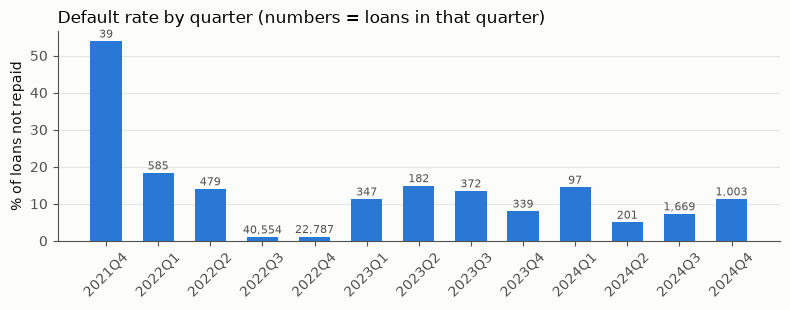

In [6]:
q = tr.groupby(tr.disbursement_date.dt.to_period("Q")).target.agg(["size", "mean"])
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(q.index.astype(str), q["mean"] * 100, color=BLUE, width=0.6)
for i, (n, m) in enumerate(zip(q["size"], q["mean"])):
    ax.text(i, m * 100 + 1, f"{n:,}", ha="center", fontsize=8, color=INK2)
ax.set_ylabel("% of loans not repaid"); ax.set_title("Default rate by quarter (numbers = loans in that quarter)", loc="left")
ax.tick_params(axis="x", rotation=45); ax.grid(axis="y", color="#e6e5e0"); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(f"{FIG}/05_default_rate_by_quarter.png", dpi=150); plt.show()

## 2. Loan histories (step 5.1)

What can we know about a borrower's past? Note that one loan can appear as several rows, one per lender.

In [7]:
L = to_loans(tr).sort_values(["customer_id", "disbursement_date"])
n = L.groupby("customer_id").size()
first = L.groupby("customer_id").cumcount() == 0
print("rows", len(tr), "-> loans", len(L))
print("customers with 1 loan: %.0f%% | 2-5: %.0f%% | 6-20: %.0f%% | over 20: %.0f%%" %
      tuple(100 * x for x in [(n == 1).mean(), n.between(2, 5).mean(), n.between(6, 20).mean(), (n > 20).mean()]))
print(f"default rate on a customer's first loan in the data: {L[first].target.mean():.1%} | later loans: {L[~first].target.mean():.1%}")
later = L.groupby("customer_id").cumcount(ascending=False) > 0
print(f"customers who borrow again after defaulting: {later[L.target == 1].mean():.0%} | after repaying: {later[L.target == 0].mean():.0%}")
print("Ghana test rows whose customer has any training history:", te[te.country_id == "Ghana"].customer_id.isin(tr.customer_id).mean())

rows 68654 -> loans 66520
customers with 1 loan: 21% | 2-5: 27% | 6-20: 38% | over 20: 13%
default rate on a customer's first loan in the data: 6.1% | later loans: 1.1%
customers who borrow again after defaulting: 10% | after repaying: 91%
Ghana test rows whose customer has any training history: 0.0


**What this means:**
- **A first loan is 5× riskier than later ones**, so experience is a strong clue.
- **Only 12% of defaulters ever borrow again.** The lender cuts them off, so almost nobody has a past default to learn from. Our data only contains people the lender kept lending to (**selection bias**).
- **No Ghanaian applicant has any history.**

## 3. Build the clues and run the self-checks (steps 5.2–5.4)

All clues come from `src/features.py`:
- history counts only what was known **on the day** (outcomes count after the due date, same-day loans excluded);
- macro uses last year's published figures.

The self-checks test this on a made-up borrower ("Ama") and on fold rules.

In [8]:
import subprocess
print(subprocess.run([sys.executable, "../src/features.py"], capture_output=True, text=True).stdout)
train, test = build(DATA)
print("train", train.shape, "(190 not-yet-due loans removed) | test", test.shape)
print("final shared clues (ADR 0012):", FEATURES)

Ama check passed
Macro and calendar check passed
Folds check passed



train (68464, 36) (190 not-yet-due loans removed) | test (18594, 32)
final shared clues (ADR 0012): ['loan_type', 'duration', 'New_versus_Repeat', 'n_prev_loans', 'n_finished', 'n_defaults', 'past_default_rate', 'no_known_history', 'days_since_last_loan', 'n_loans_last_7d', 'n_loans_last_30d', 'mean_prev_amount', 'last_amount']


## 4. Experiment helpers

The same recipe for every option:
- **logistic regression**, or **LightGBM** (many small decision trees);
- every fill-in, log and scaling step is learned **inside** the training part only;
- scores: **PR-AUC** (finding defaulters), **ROC-AUC** (ranking overall), and **lift** = PR-AUC ÷ default rate in the test part (how many times better than random).

Tests:
- `fold_customer`: new customers;
- `time_block`: learn from older loans, test on newer ones (the main test);
- new customers within the newer loans (closest to Ghana);
- borrowers with no history.

In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import average_precision_score, roc_auc_score
from lightgbm import LGBMClassifier, LGBMRegressor

GROUPS = {"base": BASE, "calendar": CALENDAR,
          "history": ["n_prev_loans", "n_finished", "n_defaults", "past_default_rate", "no_known_history", "days_since_last_loan"],
          "speed": ["n_loans_last_7d", "n_loans_last_30d"], "amounts": ["mean_prev_amount", "last_amount"],
          "macro": list(MACRO.values())}
cols_of = lambda groups: [c for g in groups for c in GROUPS[g]]
prep = preprocessor  # the shared recipe from src/features.py

def model(kind, cols):
    if kind == "logistic":
        return make_pipeline(prep(cols), LogisticRegression(class_weight="balanced", max_iter=3000))
    return make_pipeline(prep(cols), LGBMClassifier(n_estimators=300, learning_rate=0.05, class_weight="balanced",
                                                    verbose=-1, random_state=0, n_jobs=1))

def score(y, p):
    pr = average_precision_score(y, p); return pr, roc_auc_score(y, p), pr / y.mean()

def evaluate(tr, cols, kind, seeds=(0,), shuffled=False):
    X, y, r = tr[cols], tr["target"], {}
    cust = np.array([score(y[b], model(kind, cols).fit(X.loc[a], y.loc[a]).predict_proba(X.loc[b])[:, 1])
                     for s in seeds for a, b in splits(add_folds(tr, seed=s) if s else tr, "fold_customer")])
    r.update(cust_pr=cust[:, 0].mean(), cust_pr_sd=cust[:, 0].std(), cust_roc=cust[:, 1].mean())
    t, tn, nh = [], [], []
    for a, b in splits(tr, "time_block"):
        p = pd.Series(model(kind, cols).fit(X.loc[a], y.loc[a]).predict_proba(X.loc[b])[:, 1], index=b)
        t.append(score(y[b], p))
        new = b[~tr.loc[b, "customer_id"].isin(tr.loc[a, "customer_id"])]; tn.append(score(y[new], p[new]))
        nohist = b[tr.loc[b, "no_known_history"] == 1]; nh.append(score(y[nohist], p[nohist]))
    t, tn, nh = map(np.array, (t, tn, nh))
    r.update(time_pr=t[:, 0].mean(), time_roc=t[:, 1].mean(), time_lift=t[:, 2].mean(),
             newcust_lift=tn[:, 2].mean(), nohist_lift=nh[:, 2].mean())
    if shuffled:
        r["shuffled_pr"] = np.mean([score(y[b], model(kind, cols).fit(X.loc[a], y.loc[a]).predict_proba(X.loc[b])[:, 1])[0]
                                    for a, b in splits(tr, "fold_shuffled")])
    return r

## 5. Every option (step 5.5)

We build each variant of the clue table once:
- safe history;
- leaky history (outcomes counted as soon as a loan is sent);
- look-back of only the last 3 or last 5 loans, or the last 90 days;
- macro using same-year figures.

Then we run every job in parallel. **Main score:** lift on future loans (`time_lift`).

In [10]:
TABLES = {"safe": train, "leaky": build(DATA, known_when="sent")[0], "macro_same_year": build(DATA, macro_lag=0)[0],
          "window_3": build(DATA, window=3)[0], "window_5": build(DATA, window=5)[0], "window_90D": build(DATA, window="90D")[0]}
ALL = list(GROUPS); NO_MACRO = [g for g in ALL if g != "macro"]
jobs = []
for kind in ["logistic", "lightgbm"]:
    for k in range(1, len(ALL) + 1):
        for combo in itertools.combinations(ALL, k):
            jobs.append(("1 combinations", " + ".join(combo), "safe", cols_of(combo), kind))
    for c in cols_of(ALL):
        jobs.append(("2 drop one column", f"everything minus {c}", "safe", [x for x in cols_of(ALL) if x != c], kind))
    for t in ["leaky", "window_3", "window_5", "window_90D"]:
        jobs.append(("3 variants", f"everything (no macro), history {t}", t, cols_of(NO_MACRO), kind))
    jobs.append(("3 variants", "everything, macro same-year", "macro_same_year", cols_of(ALL), kind))
    for name, groups in [("base + calendar", ["base", "calendar"]), ("everything (no macro)", NO_MACRO), ("everything", ALL)]:
        jobs.append(("4 noise check", name, "safe", cols_of(groups), kind, (0, 1, 2), True))

def job(phase, option, table, cols, kind, seeds=(0,), shuffled=False):
    r = evaluate(TABLES[table], cols, kind, seeds, shuffled); r.update(phase=phase, option=option, table=table, model=kind)
    return r

res = pd.DataFrame(Parallel(n_jobs=-1)(delayed(job)(*j) for j in jobs))
res.to_csv(f"{TAB}/05_feature_comparison.csv", index=False)
print(len(res), "results saved to learnings/tables/05_feature_comparison.csv")

182 results saved to learnings/tables/05_feature_comparison.csv


### 5a. The three kinds of test, side by side (brief: "report how much the naive score was inflated")

PR-AUC of the same models with the same clues. Random guessing scores about 0.018.

,,shuffled_pr,cust_pr,cust_pr_sd,time_pr,time_lift
option,model,,,,,
base + calendar,logistic,0.208,0.205,0.031,0.104,6.674
everything (no macro),logistic,0.221,0.211,0.020,0.120,7.930
everything,logistic,0.217,0.207,0.020,0.117,7.865
base + calendar,lightgbm,0.230,0.168,0.029,0.081,5.103
everything (no macro),lightgbm,0.312,0.200,0.025,0.115,7.745
everything,lightgbm,0.315,0.204,0.026,0.107,7.140


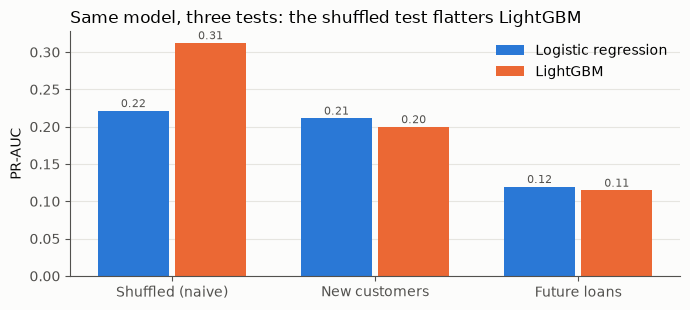

In [11]:
nc = res[res.phase == "4 noise check"].set_index(["option", "model"])
view = nc[["shuffled_pr", "cust_pr", "cust_pr_sd", "time_pr", "time_lift"]].round(3)
display(view)
x = nc.loc["everything (no macro)"]
fig, ax = plt.subplots(figsize=(7, 3.2)); w = 0.38; tests = ["shuffled_pr", "cust_pr", "time_pr"]
labels = ["Shuffled (naive)", "New customers", "Future loans"]
for i, (m, col) in enumerate([("logistic", BLUE), ("lightgbm", ORANGE)]):
    v = x.loc[m, tests].values
    bars = ax.bar(np.arange(3) + (i - 0.5) * w, v, w * 0.92, color=col, label={"logistic": "Logistic regression", "lightgbm": "LightGBM"}[m])
    for b_, val in zip(bars, v): ax.text(b_.get_x() + b_.get_width() / 2, val + 0.005, f"{val:.2f}", ha="center", fontsize=8, color=INK2)
ax.set_xticks(range(3), labels); ax.set_ylabel("PR-AUC"); ax.legend(frameon=False)
ax.set_title("Same model, three tests: the shuffled test flatters LightGBM", loc="left"); ax.grid(axis="y", color="#e6e5e0"); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(f"{FIG}/05_three_tests.png", dpi=150); plt.show()

**What this means:**
- **LightGBM looks about 50% better on the shuffled test** than on new customers, because it recognises customers it has already seen. Logistic regression barely changes.
- **On future loans both drop, and logistic regression is at least as good.**
- **We trust the future-loans test** for deployment, with new customers second.

### 5b. What each group of clues adds

For each group, we compare every combination *with* it against the same combination *without* it, then average the change in future-loan lift.

,model,group,future_lift_change,helped_future,new_customer_pr_change,helped_new_customers
0,logistic,base,4.650,31/31,0.114,31/31
1,logistic,calendar,-0.168,7/31,0.018,27/31
2,logistic,history,0.865,31/31,0.005,20/31
3,logistic,speed,0.641,31/31,0.012,30/31
4,logistic,amounts,0.205,18/31,0.005,25/31
5,logistic,macro,-0.156,4/31,0.008,20/31
6,lightgbm,base,3.622,31/31,0.096,31/31
7,lightgbm,calendar,0.200,21/31,0.029,29/31
8,lightgbm,history,0.576,22/31,0.006,19/31
9,lightgbm,speed,0.642,25/31,0.008,23/31


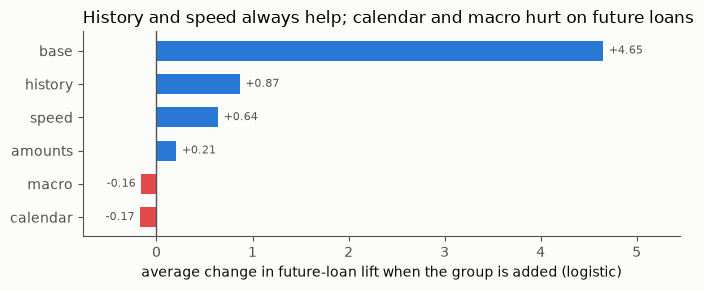

In [12]:
p1 = res[res.phase == "1 combinations"]
rows = []
for m in ["logistic", "lightgbm"]:
    d = {frozenset(o.split(" + ")): (tl, cp) for o, tl, cp in p1[p1.model == m][["option", "time_lift", "cust_pr"]].values}
    for g in ALL:
        dt = [d[s][0] - d[s - {g}][0] for s in d if g in s and len(s) > 1]
        dc = [d[s][1] - d[s - {g}][1] for s in d if g in s and len(s) > 1]
        rows.append(dict(model=m, group=g, future_lift_change=np.mean(dt), helped_future=f"{sum(v > 0 for v in dt)}/{len(dt)}",
                         new_customer_pr_change=np.mean(dc), helped_new_customers=f"{sum(v > 0 for v in dc)}/{len(dc)}"))
effects = pd.DataFrame(rows); effects.to_csv(f"{TAB}/05_group_effects.csv", index=False); display(effects.round(3))
e = effects[effects.model == "logistic"].set_index("group")["future_lift_change"].sort_values()
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(e.index, e.values, color=[RED if v < 0 else BLUE for v in e.values], height=0.6)
for i, v in enumerate(e.values): ax.text(v + (0.06 if v >= 0 else -0.06), i, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=8, color=INK2)
ax.axvline(0, color=INK2, lw=1); ax.set_xlabel("average change in future-loan lift when the group is added (logistic)")
ax.set_title("History and speed always help; calendar and macro hurt on future loans", loc="left")
ax.set_xlim(e.min() - 0.6, e.max() + 0.8); fig.tight_layout(); fig.savefig(f"{FIG}/05_group_effects.png", dpi=150); plt.show()

### 5c. Top and bottom combinations, single columns removed, and variants

In [13]:
cols = ["option", "cust_pr", "time_pr", "time_roc", "time_lift", "newcust_lift", "nohist_lift"]
for m in ["logistic", "lightgbm"]:
    x = p1[p1.model == m].sort_values("time_lift", ascending=False)
    print(f"--- {m}: best 8 and worst 3 of 63 combinations ---"); display(pd.concat([x.head(8), x.tail(3)])[cols].round(3))
for ph in ["2 drop one column", "3 variants"]:
    print(f"--- {ph} ---"); display(res[res.phase == ph].sort_values(["model", "time_lift"], ascending=[True, False])[["model"] + cols].round(3))

--- logistic: best 8 and worst 3 of 63 combinations ---


,option,cust_pr,time_pr,time_roc,time_lift,newcust_lift,nohist_lift
25,base + history + speed,0.208,0.123,0.802,8.362,3.518,3.546
48,base + history + speed + macro,0.210,0.123,0.803,8.352,3.487,3.500
29,base + speed + macro,0.215,0.120,0.784,8.184,3.545,3.527
60,base + history + speed + amounts + macro,0.208,0.120,0.795,8.165,3.465,3.474
47,base + history + speed + amounts,0.210,0.120,0.794,8.145,3.477,3.505
7,base + history,0.200,0.119,0.806,8.116,3.552,3.525
8,base + speed,0.214,0.119,0.786,8.096,3.511,3.486
28,base + speed + amounts,0.217,0.118,0.765,8.062,3.530,3.536
1,calendar,0.063,0.021,0.470,1.049,1.069,0.949
5,macro,0.058,0.016,0.439,0.936,0.987,0.981


--- lightgbm: best 8 and worst 3 of 63 combinations ---


,option,cust_pr,time_pr,time_roc,time_lift,newcust_lift,nohist_lift
148,base + calendar + history + speed + macro,0.206,0.113,0.774,7.823,3.642,3.540
147,base + calendar + history + speed + amounts,0.207,0.115,0.775,7.745,3.535,3.420
119,base + speed + amounts,0.191,0.112,0.766,7.680,3.394,3.332
141,base + speed + amounts + macro,0.201,0.112,0.766,7.674,3.403,3.328
132,base + calendar + history + speed,0.203,0.110,0.768,7.630,3.459,3.333
133,base + calendar + history + amounts,0.205,0.110,0.772,7.404,3.416,3.376
114,base + calendar + amounts,0.206,0.110,0.695,7.371,3.348,3.264
149,base + calendar + history + amounts + macro,0.207,0.110,0.773,7.370,3.385,3.325
105,calendar + macro,0.100,0.020,0.495,1.080,1.189,1.195
96,macro,0.058,0.018,0.500,1.000,1.000,1.000


--- 2 drop one column ---


,model,option,cust_pr,time_pr,time_roc,time_lift,newcust_lift,nohist_lift
166,lightgbm,everything minus n_loans_last_7d,0.211,0.109,0.771,7.460,3.409,3.319
156,lightgbm,everything minus New_versus_Repeat,0.210,0.111,0.768,7.413,3.365,3.311
157,lightgbm,everything minus month,0.205,0.110,0.765,7.398,3.426,3.313
165,lightgbm,everything minus days_since_last_loan,0.208,0.110,0.776,7.382,3.245,3.173
167,lightgbm,everything minus n_loans_last_30d,0.214,0.107,0.768,7.236,3.302,3.215
168,lightgbm,everything minus mean_prev_amount,0.213,0.108,0.768,7.193,3.414,3.308
162,lightgbm,everything minus n_defaults,0.212,0.107,0.765,7.140,3.390,3.259
163,lightgbm,everything minus past_default_rate,0.212,0.107,0.765,7.140,3.390,3.259
164,lightgbm,everything minus no_known_history,0.212,0.107,0.765,7.140,3.390,3.259
170,lightgbm,everything minus inflation,0.212,0.107,0.765,7.140,3.390,3.259


--- 3 variants ---


,model,option,cust_pr,time_pr,time_roc,time_lift,newcust_lift,nohist_lift
177,lightgbm,"everything (no macro), history window_90D",0.206,0.109,0.762,7.423,3.419,3.277
176,lightgbm,"everything (no macro), history window_5",0.208,0.109,0.773,7.282,3.323,3.248
175,lightgbm,"everything (no macro), history window_3",0.204,0.108,0.766,7.194,3.399,3.314
178,lightgbm,"everything, macro same-year",0.208,0.107,0.765,7.140,3.390,3.259
174,lightgbm,"everything (no macro), history leaky",0.211,0.105,0.769,6.978,3.330,2.723
83,logistic,"everything (no macro), history leaky",0.211,0.119,0.790,7.934,3.534,2.917
84,logistic,"everything (no macro), history window_3",0.210,0.120,0.790,7.933,3.537,3.526
85,logistic,"everything (no macro), history window_5",0.210,0.119,0.789,7.912,3.546,3.533
87,logistic,"everything, macro same-year",0.209,0.115,0.773,7.852,3.501,3.507
86,logistic,"everything (no macro), history window_90D",0.215,0.116,0.788,7.609,3.544,3.473


**What this means:**
- **Most important single columns:** `duration` and `loan_type`. Removing either costs the most.
- **For LightGBM, removing any macro column changes nothing,** so it never used them.
- **Leaky history scores the same overall** but is worse for borrowers with no history.
- **Look-back windows don't beat "all past loans".**

## 6. Is the winner real? Bootstrap on future loans

We resample the test loans 300 times and recompute lift. If two options' 95% ranges overlap a lot, the gap could be luck. A **paired** difference (same resample for both options) is the fairer comparison.

In [14]:
y = train.target
cands = {"L base+history+speed": ("logistic", cols_of(["base", "history", "speed"])),
         "L FEATURES (base+history+speed+amounts)": ("logistic", FEATURES),
         "L everything (no macro)": ("logistic", cols_of(NO_MACRO)),
         "L base+calendar (Liza's set)": ("logistic", cols_of(["base", "calendar"])),
         "G everything (no macro)": ("lightgbm", cols_of(NO_MACRO)),
         "G FEATURES": ("lightgbm", FEATURES)}
pred = {}
for name, (k, cl) in cands.items():
    p = pd.Series(index=train.index, dtype=float)
    for a, b in splits(train, "time_block"): p[b] = model(k, cl).fit(train.loc[a, cl], y[a]).predict_proba(train.loc[b, cl])[:, 1]
    pred[name] = p
blocks = [b for _, b in splits(train, "time_block")]; rng = np.random.default_rng(0)
lift = lambda p, idx: np.mean([average_precision_score(y[i], p[i]) / y[i].mean() for i in idx])
boot = {n: [] for n in pred}
for _ in range(300):
    idx = [rng.choice(b, len(b)) for b in blocks]
    for n in pred: boot[n].append(lift(pred[n], idx))
ref = "L FEATURES (base+history+speed+amounts)"
out = pd.DataFrame([{"option": n, "future_lift": lift(pred[n], blocks), "ci_low": np.percentile(boot[n], 2.5), "ci_high": np.percentile(boot[n], 97.5),
                     "diff_vs_FEATURES_low": np.percentile(np.subtract(boot[n], boot[ref]), 2.5),
                     "diff_vs_FEATURES_high": np.percentile(np.subtract(boot[n], boot[ref]), 97.5)} for n in pred])
out.to_csv(f"{TAB}/05_bootstrap.csv", index=False); out.round(2)

,option,future_lift,ci_low,ci_high,diff_vs_FEATURES_low,diff_vs_FEATURES_high
0,L base+history+speed,8.36,6.81,10.56,0.02,0.38
1,L FEATURES (base+history+speed+amounts),8.14,6.66,10.31,0.00,0.00
2,L everything (no macro),7.93,6.43,10.04,-0.75,0.24
3,L base+calendar (Liza's set),6.67,5.25,8.83,-2.00,-0.86
4,G everything (no macro),7.74,6.16,9.66,-1.48,0.55
5,G FEATURES,7.16,5.76,9.17,-1.73,-0.28


**What this means:**
- **Liza's set alone is clearly worse:** its whole difference range is below zero, so history adds real value.
- **The top options overlap.** Base + history + speed is a hair better for Task 2 (difference range +0.02 to +0.38), but tiny compared with the overall range.

## 7. Task 1 (loan amount): do the clues help?

Both tasks must share clues, so we check the candidates on predicting the log of the loan amount. The score is the average error on the log scale; lower is better. 0.58 means a typical guess is off by about 1.8×.

In [15]:
ya = np.log(train.Total_Amount); rows = []
def reg(kind, cl): return make_pipeline(prep(cl), Ridge() if kind == "linear" else LGBMRegressor(n_estimators=300, learning_rate=0.05, verbose=-1, random_state=0))
for name, cl in [("mean baseline", None), ("base + calendar (Liza's set)", cols_of(["base", "calendar"])),
                 ("base + history + speed", cols_of(["base", "history", "speed"])), ("FEATURES (+ amounts)", FEATURES),
                 ("everything (no macro)", cols_of(NO_MACRO))]:
    for kind in (["linear", "lightgbm"] if cl else ["mean"]):
        r = {"clues": name, "model": kind}
        for sch in ["fold_customer", "time_block"]:
            e = [np.mean(np.abs(ya[b] - (np.full(len(b), ya[a].mean()) if cl is None else reg(kind, cl).fit(train.loc[a, cl], ya[a]).predict(train.loc[b, cl]))))
                 for a, b in splits(train, sch)]
            r[f"{sch} error (log)"] = np.mean(e)
        rows.append(r)
t1 = pd.DataFrame(rows); t1.to_csv(f"{TAB}/05_task1_check.csv", index=False); t1.round(3)

,clues,model,fold_customer error (log),time_block error (log)
0,mean baseline,mean,0.978,0.971
1,base + calendar (Liza's set),linear,0.912,0.918
2,base + calendar (Liza's set),lightgbm,0.910,0.917
3,base + history + speed,linear,0.910,0.914
4,base + history + speed,lightgbm,0.908,0.939
5,FEATURES (+ amounts),linear,0.598,0.612
6,FEATURES (+ amounts),lightgbm,0.579,0.575
7,everything (no macro),linear,0.598,0.762
8,everything (no macro),lightgbm,0.574,0.569


**What this means:**
- **Past amounts are the key clue for Task 1:** error falls from about 0.91 to about 0.58.
- **Calendar breaks the linear model on future loans,** again.

## Decision ([ADR 0012](../docs/adr/0012-final-feature-set.md))
**`FEATURES` = base + history + speed + amounts, for both tasks. No calendar, no macro.** Logistic regression is at least as good as LightGBM on future loans.